# Fuel Prices

Dataset containing weekly road fuel prices for Petrol and Diesel sourced from Department of Energy Security and Net Zero

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df= pd.read_excel("Weekly Road fuel prices 2018-2026.xlsx")
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (451, 7)


,Date,ULSP (Ultra low sulphur unleaded petrol) Pump price in pence/litre,ULSD (Ultra low sulphur diesel) Pump price in pence/litre,ULSP (Ultra low sulphur unleaded petrol) Duty rate in pence/litre,ULSD (Ultra low sulphur diesel) Duty rate in pence/litre,ULSP (Ultra low sulphur unleaded petrol) VAT percentage rate,ULSD (Ultra low sulphur diesel) VAT percentage rate
0,2018-01-01,120.19,123.51,57.95,57.95,20,20
1,2018-01-08,120.52,123.97,57.95,57.95,20,20
2,2018-01-15,120.96,124.58,57.95,57.95,20,20
3,2018-01-22,121.50,125.07,57.95,57.95,20,20
4,2018-01-29,121.69,125.32,57.95,57.95,20,20


# Data Cleaning

In [2]:
#removes all leading and trailing whitespace from the column names
df.columns = df.columns.str.strip()

In [3]:
print("Missing values:", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

Missing values: Date                                                                  0
ULSP (Ultra low sulphur unleaded petrol) Pump price in pence/litre    0
ULSD (Ultra low sulphur diesel) Pump price in pence/litre             0
ULSP (Ultra low sulphur unleaded petrol) Duty rate in pence/litre     0
ULSD (Ultra low sulphur diesel) Duty rate in pence/litre              0
ULSP (Ultra low sulphur unleaded petrol) VAT percentage rate          0
ULSD (Ultra low sulphur diesel) VAT percentage rate                   0
dtype: int64
Duplicates: 0


In [4]:
# Make sure Date is datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

In [5]:
# Remove exact duplicate rows if present
df = df.drop_duplicates()
# Sort chronologically
df = df.sort_values("Date").reset_index(drop=True)

In [6]:
# Check for invalid dates
print("Missing/invalid dates:", df["Date"].isna().sum())


Missing/invalid dates: 0


In [7]:
# Summary statistics
print(df.describe())

                      Date  \
count                  451   
mean   2022-04-25 00:00:00   
min    2018-01-01 00:00:00   
25%    2020-02-27 12:00:00   
50%    2022-04-25 00:00:00   
75%    2024-06-20 12:00:00   
max    2026-08-17 00:00:00   
std                    NaN   

       ULSP (Ultra low sulphur unleaded petrol) Pump price in pence/litre  \
count                                         451.000000                    
mean                                          136.444213                    
min                                           104.870000                    
25%                                           125.680000                    
50%                                           134.400000                    
75%                                           146.055000                    
max                                           191.550000                    
std                                            16.153515                    

       ULSD (Ultra low sulphur dies

The focus is primarily on the 2022–2023 UK energy crisis

In [8]:
fuel_crisis = df[
    (df["Date"] >= "2022-01-01") &
    (df["Date"] <= "2023-12-31")
].copy()

print(fuel_crisis.shape)
print("earliest date in that period", fuel_crisis["Date"].min())
print("latest date in that period", fuel_crisis["Date"].max())

(104, 7)
earliest date in that period 2022-01-03 00:00:00
latest date in that period 2023-12-25 00:00:00


# EDA

In [9]:
petrol_col = "ULSP (Ultra low sulphur unleaded petrol) Pump price in pence/litre"
diesel_col = "ULSD (Ultra low sulphur diesel) Pump price in pence/litre"

fuel_crisis[
        ["Date", petrol_col, diesel_col]
    ].head()

,Date,ULSP (Ultra low sulphur unleaded petrol) Pump price in pence/litre,ULSD (Ultra low sulphur diesel) Pump price in pence/litre
209,2022-01-03,145.04,148.85
210,2022-01-10,144.82,148.65
211,2022-01-17,144.80,148.70
212,2022-01-24,144.87,148.81
213,2022-01-31,145.74,149.68


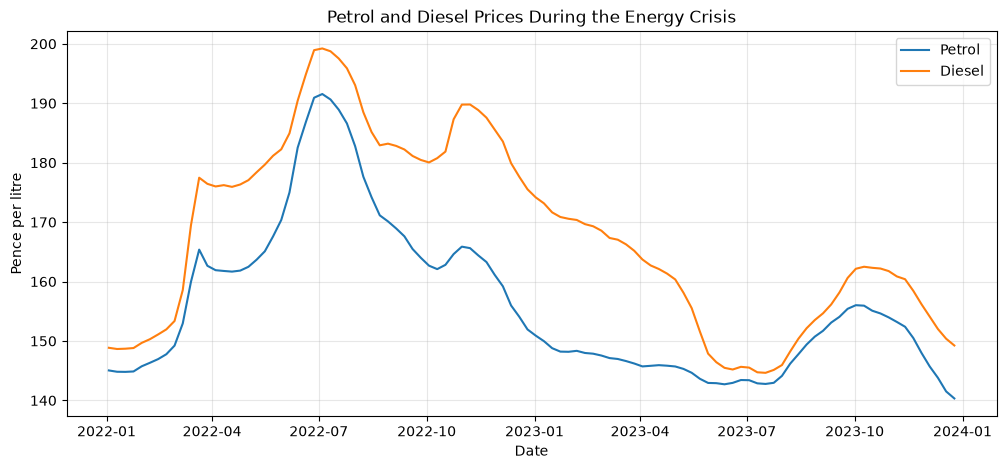

In [10]:
# Comparing diesel and petrol prices over time
plt.figure(figsize=(12, 5))

plt.plot(
    fuel_crisis["Date"],
    fuel_crisis[petrol_col],
    label="Petrol"
)

plt.plot(
    fuel_crisis["Date"],
    fuel_crisis[diesel_col],
    label="Diesel"
)

plt.title("Petrol and Diesel Prices During the Energy Crisis")
plt.xlabel("Date")
plt.ylabel("Pence per litre")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [11]:
#Monthly average prices
monthly_prices = (
    fuel_crisis
    .set_index("Date")[[petrol_col, diesel_col]]
    .resample("MS")
    .mean()
    .reset_index()
)
print(monthly_prices.head())

        Date  \
0 2022-01-01   
1 2022-02-01   
2 2022-03-01   
3 2022-04-01   
4 2022-05-01   

   ULSP (Ultra low sulphur unleaded petrol) Pump price in pence/litre  \
0                                           145.0540                    
1                                           147.5675                    
2                                           160.2325                    
3                                           161.8000                    
4                                           165.8400                    

   ULSD (Ultra low sulphur diesel) Pump price in pence/litre  
0                                           148.9380          
1                                           151.6775          
2                                           170.4875          
3                                           176.1200          
4                                           179.7060          


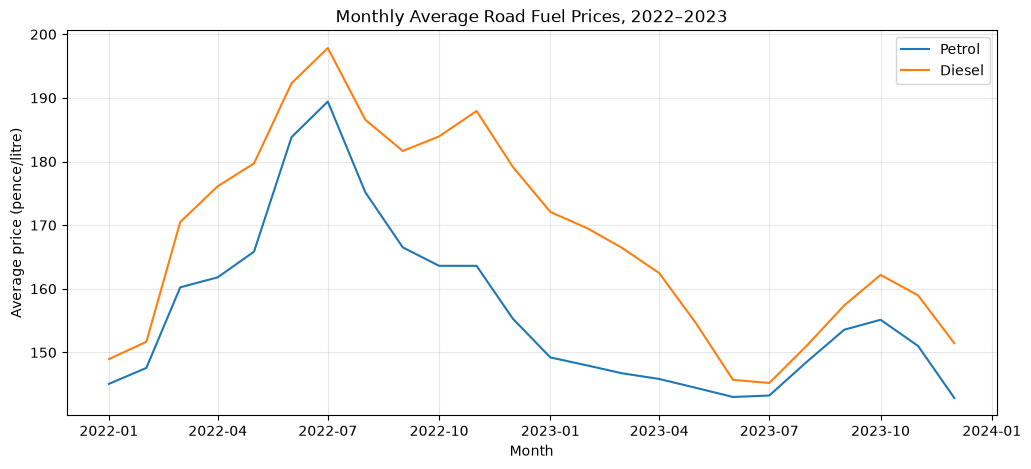

In [12]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_prices["Date"],
    monthly_prices[petrol_col],
    label="Petrol"
)

plt.plot(
    monthly_prices["Date"],
    monthly_prices[diesel_col],
    label="Diesel"
)

plt.title("Monthly Average Road Fuel Prices, 2022–2023")
plt.xlabel("Month")
plt.ylabel("Average price (pence/litre)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

Mid-2022 Energy Shock Peak: Fueled by the 2022 global energy crisis, both fuels surged sharply in mid-2022, reaching record highs around 190p/L for Petrol and nearly 198p/L for Diesel in July 2022. 

Diesel consistently traded higher than petrol throughout the period, with the gap widening significantly in late 2022. The parliamentary analysis documents how the premium gap between petrol and diesel reached record levels in late 2022. It notes that Europe relied heavily on Russian imports for roughly half of its middle distillate needs (diesel and gasoil) prior to the 2022 sanctions.
https://commonslibrary.parliament.uk/research-briefings/sn04712/

In [13]:
#Yearly comparison
fuel_crisis["Year"] = fuel_crisis["Date"].dt.year

yearly_prices = (
    fuel_crisis
    .groupby("Year")[[petrol_col, diesel_col]]
    .mean()
)

print(yearly_prices)

      ULSP (Ultra low sulphur unleaded petrol) Pump price in pence/litre  \
Year                                                                       
2022                                         164.642500                    
2023                                         147.650192                    

      ULSD (Ultra low sulphur diesel) Pump price in pence/litre  
Year                                                             
2022                                         177.778077          
2023                                         158.124231          


# Feature Engineering

Average road fuel price: Cost of private road mobility during the energy crisis.

In [14]:
fuel_crisis["Average_Fuel_Price"] = (
    fuel_crisis[petrol_col] +
    fuel_crisis[diesel_col]
) / 2

Diesel–petrol price gap : To check whether diesel users were experiencing a larger fuel-cost burden than petrol users.

In [15]:
fuel_crisis["Diesel_Petrol_Price_Gap"] = (
    fuel_crisis[diesel_col] -
    fuel_crisis[petrol_col]
)

Weekly Petrol and Diesel Price Change : To check fuel-price volatility

In [16]:
fuel_crisis["Petrol_Weekly_Change"] = (
    fuel_crisis[petrol_col].pct_change() * 100
)
fuel_crisis["Diesel_Weekly_Change"] = (
    fuel_crisis[diesel_col].pct_change() * 100
)

In [17]:
fuel_crisis[
        [
            "Date",
            petrol_col,
            diesel_col,
            "Average_Fuel_Price",
            "Diesel_Petrol_Price_Gap",
            "Petrol_Weekly_Change",
            "Diesel_Weekly_Change"
        ]
    ].head(10)

,Date,ULSP (Ultra low sulphur unleaded petrol) Pump price in pence/litre,ULSD (Ultra low sulphur diesel) Pump price in pence/litre,Average_Fuel_Price,Diesel_Petrol_Price_Gap,Petrol_Weekly_Change,Diesel_Weekly_Change
209,2022-01-03,145.04,148.85,146.945,3.81,NaN,NaN
210,2022-01-10,144.82,148.65,146.735,3.83,-0.151682,-0.134363
211,2022-01-17,144.80,148.70,146.750,3.90,-0.013810,0.033636
212,2022-01-24,144.87,148.81,146.840,3.94,0.048343,0.073974
213,2022-01-31,145.74,149.68,147.710,3.94,0.600538,0.584638
214,2022-02-07,146.33,150.30,148.315,3.97,0.404831,0.414217
215,2022-02-14,146.95,151.10,149.025,4.15,0.423700,0.532269
216,2022-02-21,147.77,151.95,149.860,4.18,0.558013,0.562541
217,2022-02-28,149.22,153.36,151.290,4.14,0.981255,0.927937
218,2022-03-07,152.95,158.56,155.755,5.61,2.499665,3.390715


Monthly and Annual fuel dataframe

In [18]:
monthly_fuel = (
    fuel_crisis
    .set_index("Date")
    .resample("MS")
    .agg({
        petrol_col: "mean",
        diesel_col: "mean",
        "Average_Fuel_Price": "mean",
        "Diesel_Petrol_Price_Gap": "mean"
    })
    .reset_index()
)
monthly_fuel["Year"] = monthly_fuel["Date"].dt.year
monthly_fuel["Month"] = monthly_fuel["Date"].dt.month
monthly_fuel.head()

,Date,ULSP (Ultra low sulphur unleaded petrol) Pump price in pence/litre,ULSD (Ultra low sulphur diesel) Pump price in pence/litre,Average_Fuel_Price,Diesel_Petrol_Price_Gap,Year,Month
0,2022-01-01,145.0540,148.9380,146.9960,3.884,2022,1
1,2022-02-01,147.5675,151.6775,149.6225,4.110,2022,2
2,2022-03-01,160.2325,170.4875,165.3600,10.255,2022,3
3,2022-04-01,161.8000,176.1200,168.9600,14.320,2022,4
4,2022-05-01,165.8400,179.7060,172.7730,13.866,2022,5


In [19]:
annual_fuel = (
    fuel_crisis
    .groupby(fuel_crisis["Date"].dt.year)
    .agg({
        petrol_col: "mean",
        diesel_col: "mean",
        "Average_Fuel_Price": "mean",
        "Diesel_Petrol_Price_Gap": "mean"
    })
    .reset_index()
    .rename(columns={"Date": "Year"})
)

annual_fuel

,Year,ULSP (Ultra low sulphur unleaded petrol) Pump price in pence/litre,ULSD (Ultra low sulphur diesel) Pump price in pence/litre,Average_Fuel_Price,Diesel_Petrol_Price_Gap
0,2022,164.642500,177.778077,171.210288,13.135577
1,2023,147.650192,158.124231,152.887212,10.474038


Saving the features for fuel prices on Monthly and Annual basis to new datasets as shown below. Going forward with Annual Dataset to avoid memory consumption and unwanted complex data integration in Master Notebook to attain final merged dataset.

In [20]:
monthly_fuel.to_excel(
    "monthly_fuel_prices_2022_2023.xlsx",
    index=False
)
annual_fuel.to_excel(
    "annual_fuel_features_2022_2023.xlsx",
    index=False
)
